# Анализ трудоустройства выпускников (ВТР-2021)

Данные: Росстат, выборочное наблюдение трудоустройства выпускников 2021 года.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")


In [3]:
# Загружаем данные
df = pd.read_excel('data/ВТР_2021.xlsx', sheet_name='Sheet1',
    usecols=['RESP', 'GOD', 'MES', 'OKRYG_SV', 'NASOBRAZ',
             'FOR_ZAC', 'NAS_VOZR', 'BZ_DOX', 'TRUD_RB5', 'DPS_RB5'])
print('Размер данных:', df.shape)
df.head()


Размер данных: (21526, 10)


In [4]:
# Создаем словарь для перекодировки значений
okrug_mapping = {
    1: 'Центральный ФО',
    2: 'Северо-Западный ФО',
    3: 'Южный ФО',
    4: 'Северо-Кавказский ФО',
    5: 'Приволжский ФО',
    6: 'Уральский ФО',
    7: 'Сибирский ФО',
    8: 'Дальневосточный ФО'
}

# Применяем перекодировку
df['OKRYG_SV'] = df['OKRYG_SV'].replace(okrug_mapping)

# Создаем словарь для перекодировки значений образования
education_mapping = {
    1: 'Высшее - специалитет/магистратура',
    3: 'СПО - специалисты среднего звена',
    4: 'СПО - квалифицированные рабочие',
    8: 'Послевузовское профессиональное',
    9: 'Высшее - бакалавриат'
}

# Применяем перекодировку
df['NASOBRAZ'] = df['NASOBRAZ'].replace(education_mapping)

# Создаем словарь для перекодировки форм обучения
education_form_mapping = {
    1: 'Очная',
    2: 'Очно-заочная',
    3: 'Заочная'
}

# Применяем перекодировку
df['FOR_ZAC'] = df['FOR_ZAC'].replace(education_form_mapping)

# Создаем словарь для перекодировки форм обучения
work_experience_mapping = {
    1: 'Имеют опыт',
    2: 'Не имеют опыта'
}

# Применяем перекодировку
df['BZ_DOX'] = df['BZ_DOX'].replace(work_experience_mapping)

In [5]:
# Проверка размерности датафрейма
print("\nРазмер датафрейма:", df.shape)

# Проверка типов данных
print("\nТипы данных в колонках:")
print(df.dtypes)

# Проверка на наличие пропущенных значений
print("\nКоличество пропущенных значений:")
print(df.isnull().sum())


Размер датафрейма: (21526, 10)

Типы данных в колонках:
RESP          int64
GOD           int64
MES           int64
OKRYG_SV     object
NAS_VOZR      int64
NASOBRAZ     object
FOR_ZAC      object
TRUD_RB5    float64
DPS_RB5     float64
BZ_DOX       object
dtype: object

Количество пропущенных значений:
RESP        0
GOD         0
MES         0
OKRYG_SV    0
NAS_VOZR    0
NASOBRAZ    0
FOR_ZAC     0
TRUD_RB5    0
DPS_RB5     0
BZ_DOX      0
dtype: int64


## Описательная статистика

Описательная статистика для возраста:
count    21526.000000
mean        25.592679
std          5.418172
min         18.000000
25%         22.000000
50%         24.000000
75%         27.000000
max         65.000000
Name: NAS_VOZR, dtype: float64

Тип переменной: int64
Количество уникальных значений: 47

Показатели вариации:
Размах вариации: 47
Интерквартильный размах: 5.0
Коэффициент вариации: 21.17%

Показатели формы распределения:
Коэффициент асимметрии: 2.40
Коэффициент эксцесса: 7.64

Тест на нормальность распределения:
p-value: 0.0
Распределение значимо отличается от нормального


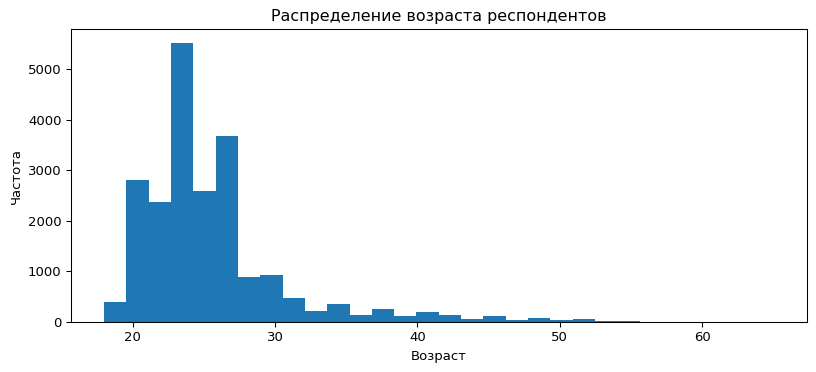

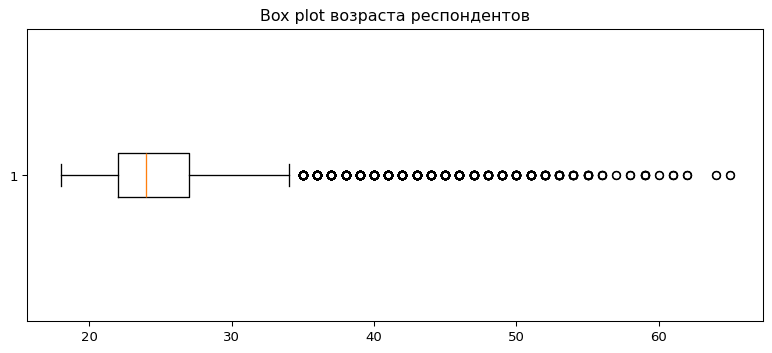

In [7]:
feature = 'NAS_VOZR'


# Базовое описание переменной
print("Описательная статистика для возраста:")
print(df[feature].describe())

# Определение типа переменной
print("\nТип переменной:", df[feature].dtype)
print("Количество уникальных значений:", df[feature].nunique())

# Графический анализ
plt.figure(figsize=(10, 4))
plt.hist(df[feature].dropna(), bins=30)
plt.title('Распределение возраста респондентов')
plt.xlabel('Возраст')
plt.ylabel('Частота')
plt.show()

# Box plot для выявления выбросов
plt.figure(figsize=(10, 4))
plt.boxplot(df[feature].dropna(), vert=False)
plt.title('Box plot возраста респондентов')
plt.show()

# Расчет показателей вариации
range_var = df[feature].max() - df[feature].min()
q75, q25 = np.percentile(df[feature], [75, 25])
iqr = q75 - q25
cv = (df[feature].std() / df[feature].mean()) * 100

print("\nПоказатели вариации:")
print(f"Размах вариации: {range_var}")
print(f"Интерквартильный размах: {iqr}")
print(f"Коэффициент вариации: {cv:.2f}%")

# Анализ формы распределения
skewness = df[feature].skew()
kurtosis = df[feature].kurtosis()

print("\nПоказатели формы распределения:")
print(f"Коэффициент асимметрии: {skewness:.2f}")
print(f"Коэффициент эксцесса: {kurtosis:.2f}")

# Проверка на нормальность распределения
stat, p_value = stats.normaltest(df[feature])
print("\nТест на нормальность распределения:")
print(f"p-value: {p_value}")
if p_value < 0.05:
    print("Распределение значимо отличается от нормального")
else:
    print("Распределение можно считать нормальным")

Описательная статистика для времени поиска работы:
count    21526.000000
mean         2.463927
std          5.689707
min          0.000000
25%          0.000000
50%          0.500000
75%          2.000000
max         60.000000
Name: DPS_RB5, dtype: float64

Тип переменной: float64
Количество уникальных значений: 18

Показатели вариации:
Размах вариации: 60.0
Интерквартильный размах: 2.0
Коэффициент вариации: 230.92%

Показатели формы распределения:
Коэффициент асимметрии: 4.32
Коэффициент эксцесса: 23.87

Тест на нормальность распределения:
p-value: 0.0
Распределение значимо отличается от нормального


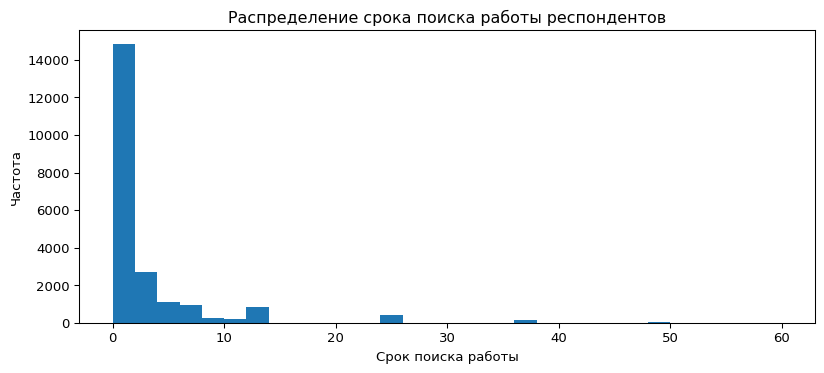

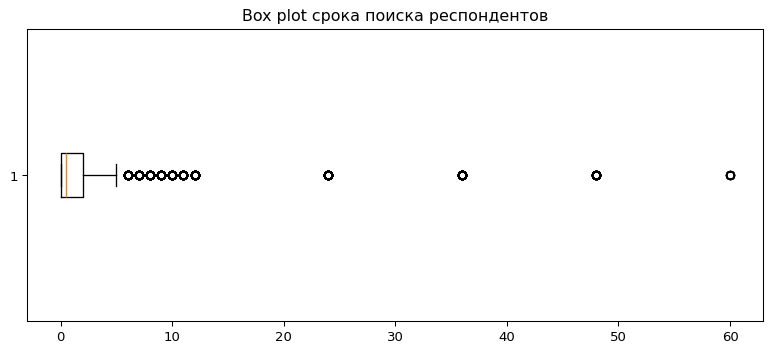

In [8]:
feature = 'DPS_RB5'


# Базовое описание переменной
print("Описательная статистика для времени поиска работы:")
print(df[feature].describe())

# Определение типа переменной
print("\nТип переменной:", df[feature].dtype)
print("Количество уникальных значений:", df[feature].nunique())

# Графический анализ
plt.figure(figsize=(10, 4))
plt.hist(df[feature].dropna(), bins=30)
plt.title('Распределение срока поиска работы респондентов')
plt.xlabel('Срок поиска работы')
plt.ylabel('Частота')
plt.show()

# Box plot для выявления выбросов
plt.figure(figsize=(10, 4))
plt.boxplot(df[feature].dropna(), vert=False)
plt.title('Box plot срока поиска респондентов')
plt.show()

# Расчет показателей вариации
range_var = df[feature].max() - df[feature].min()
q75, q25 = np.percentile(df[feature], [75, 25])
iqr = q75 - q25
cv = (df[feature].std() / df[feature].mean()) * 100

print("\nПоказатели вариации:")
print(f"Размах вариации: {range_var}")
print(f"Интерквартильный размах: {iqr}")
print(f"Коэффициент вариации: {cv:.2f}%")

# Анализ формы распределения
skewness = df[feature].skew()
kurtosis = df[feature].kurtosis()

print("\nПоказатели формы распределения:")
print(f"Коэффициент асимметрии: {skewness:.2f}")
print(f"Коэффициент эксцесса: {kurtosis:.2f}")

# Проверка на нормальность распределения
stat, p_value = stats.normaltest(df[feature])
print("\nТест на нормальность распределения:")
print(f"p-value: {p_value}")
if p_value < 0.05:
    print("Распределение значимо отличается от нормального")
else:
    print("Распределение можно считать нормальным")

## Группировки и сравнение

In [10]:
def correlation_ratio(categories, values):
    # Отбираем наблюдения без пропусков
    temp = pd.DataFrame({'group': categories, 'value': values}).dropna()
    if temp.empty:
        return np.nan
    means = temp.groupby('group')['value'].mean()
    counts = temp.groupby('group')['value'].size()
    overall = temp['value'].mean()
    total = ((temp['value'] - overall) ** 2).sum()
    return np.sqrt((counts * (means - overall) ** 2).sum() / total) if total else np.nan


def interpret_correlation(corr):
    if corr < 0.3:
        return 'слабая'
    if corr < 0.5:
        return 'умеренная'
    if corr < 0.7:
        return 'заметная'
    if corr < 0.9:
        return 'высокая'
    return 'очень высокая'


           count  mean  median   std
age_group                           
18-25      13659  2.46     0.5  5.41
26-35       6549  2.78     0.5  6.41
36-45        992  1.09     0.0  4.29
46+          326  0.65     0.0  4.08
Корреляционное отношение: 0.072, η²: 0.005
Kruskal–Wallis: KruskalResult(statistic=np.float64(641.414711390236), pvalue=np.float64(1.0586445052463422e-138))


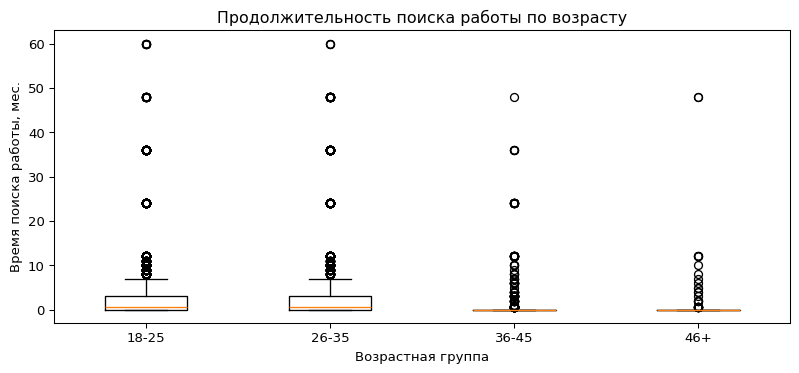

In [11]:
# Возрастные группы
age_df = df.dropna(subset=['NAS_VOZR', 'DPS_RB5']).copy()
age_df['age_group'] = pd.cut(age_df['NAS_VOZR'],
    bins=[17, 25, 35, 45, np.inf], labels=['18-25', '26-35', '36-45', '46+'])
print(age_df.groupby('age_group', observed=True)['DPS_RB5'].agg(['count','mean','median','std']).round(2))
eta = correlation_ratio(age_df['age_group'], age_df['DPS_RB5'])
print(f'Корреляционное отношение: {eta:.3f}, η²: {eta**2:.3f}')
plt.figure(figsize=(10, 4))
plt.boxplot([g['DPS_RB5'].dropna().values for _, g in age_df.groupby('age_group', observed=True)], tick_labels=['18-25', '26-35', '36-45', '46+'])
plt.xlabel('Возрастная группа'); plt.ylabel('Время поиска работы, мес.')
plt.title('Продолжительность поиска работы по возрасту')
plt.show()

age_groups = [g['DPS_RB5'].values for _, g in age_df.groupby('age_group', observed=True)]
if len(age_groups)>1:
    print('Kruskal–Wallis:', stats.kruskal(*age_groups))


In [12]:
# Форма обучения: код 0 не относится к трём указанным формам
form_df = df[df['FOR_ZAC'].isin(['Очная', 'Очно-заочная', 'Заочная'])].copy()
print('Наблюдений по формам обучения:', len(form_df))
print(form_df.groupby('FOR_ZAC')['DPS_RB5'].agg(['count','mean','median','std']).round(2))
eta = correlation_ratio(form_df['FOR_ZAC'], form_df['DPS_RB5'])
print(f'Корреляционное отношение: {eta:.3f}, η²: {eta**2:.3f}')
print('Kruskal–Wallis:', stats.kruskal(*[g['DPS_RB5'].values for _,g in form_df.groupby('FOR_ZAC')]))


Наблюдений по формам обучения: 20711
              count  mean  median   std
FOR_ZAC                                
Заочная        3344  1.31     0.0  4.93
Очная         16661  2.86     0.5  5.95
Очно-заочная    706  1.50     0.0  4.39
Корреляционное отношение: 0.104, η²: 0.011
Kruskal–Wallis: KruskalResult(statistic=np.float64(1694.1357556860098), pvalue=np.float64(0.0))


In [13]:
# Образование
feature = 'NASOBRAZ'
print(df.groupby(feature)['DPS_RB5'].agg(['count','mean','median','std']).round(2))
eta = correlation_ratio(df[feature], df['DPS_RB5'])
print(f'Корреляционное отношение: {eta:.3f}, η²: {eta**2:.3f}')


                                   count  mean  median   std
NASOBRAZ                                                    
Высшее - бакалавриат                4389  2.40     0.5  5.50
Высшее - специалитет/магистратура   6582  2.41     0.5  5.49
Послевузовское профессиональное       91  1.63     0.0  4.44
СПО - квалифицированные рабочие     3091  2.64     0.5  6.40
СПО - специалисты среднего звена    7373  2.48     0.5  5.67
Корреляционное отношение: 0.017, η²: 0.000


In [14]:
# Федеральные округа
feature = 'OKRYG_SV'
print(df.groupby(feature)['DPS_RB5'].agg(['count','mean','median','std']).round(2))
eta = correlation_ratio(df[feature], df['DPS_RB5'])
print(f'Корреляционное отношение: {eta:.3f}, η²: {eta**2:.3f}')


                      count  mean  median   std
OKRYG_SV                                       
Дальневосточный ФО     1988  2.46     0.0  6.08
Приволжский ФО         4071  2.36     0.5  5.50
Северо-Западный ФО     2360  2.31     0.5  5.48
Северо-Кавказский ФО   1501  3.31     0.0  7.30
Сибирский ФО           2337  2.66     0.0  6.34
Уральский ФО           1523  2.35     0.0  5.61
Центральный ФО         5583  2.27     0.5  5.01
Южный ФО               2163  2.60     0.5  5.54
Корреляционное отношение: 0.047, η²: 0.002


## По месяцам опроса

     count  mean_search  median_search  mean_age
MES                                             
4     3808         2.35            0.5     25.60
5     3746         2.53            0.5     25.57
6     3588         2.52            0.5     25.42
7     3501         2.38            0.5     25.59
8     3459         2.43            0.5     25.61
9     3424         2.58            0.5     25.79


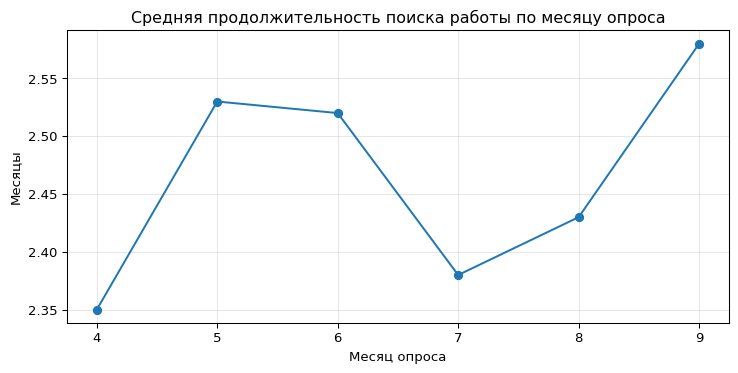

In [16]:
# Изменение средних значений по месяцам опроса, без экстраполяции
monthly = df.groupby('MES').agg(
    count=('DPS_RB5', 'size'),
    mean_search=('DPS_RB5', 'mean'),
    median_search=('DPS_RB5', 'median'),
    mean_age=('NAS_VOZR', 'mean')
).round(2)
print(monthly)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly['mean_search'], marker='o')
ax.set(title='Средняя продолжительность поиска работы по месяцу опроса',
       xlabel='Месяц опроса', ylabel='Месяцы')
ax.grid(alpha=0.3)
plt.show()


## Примечание

Представлены невзвешенные показатели выборки. Результаты группировок описывают статистические связи, а не причинное влияние. Месяц проведения опроса не является полноценным временным рядом для прогнозирования трудоустройства.
